In [6]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Python location: c:\xampp\htdocs\FoodSave\.venv\Scripts\python.exe


In [7]:
query = """
SELECT
    id,
    role,
    created_at
FROM users
ORDER BY created_at
"""

users_data = pd.read_sql(query, connection)

users_data

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd
import mysql.connector

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="foodsave_db"
)

print("FoodSave database connected! ✅")

FoodSave database connected! ✅


In [ ]:
query = """
SELECT
    id,
    role,
    created_at
FROM users
ORDER BY created_at
"""

users_data = pd.read_sql(query, connection)

users_data

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_2444\1231466450.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  users_data = pd.read_sql(query, connection)


ProgrammingError: 1054 (42S22): Unknown column 'role' in 'field list'

In [ ]:
query = """
DESCRIBE users
"""

users_structure = pd.read_sql(query, connection)

users_structure

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_2444\1987467519.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  users_structure = pd.read_sql(query, connection)


,Field,Type,Null,Key,Default,Extra
0,id,int(11),NO,PRI,NaN,auto_increment
1,username,varchar(50),NO,UNI,NaN,
2,email,varchar(100),NO,UNI,NaN,
3,password,varchar(255),NO,,NaN,
4,user_type,"enum('admin','donor','ngo','volunteer','driver')",NO,,NaN,
5,full_name,varchar(150),NO,,NaN,
6,organization_name,varchar(150),YES,,NaN,
7,phone,varchar(20),YES,,NaN,
8,address,text,YES,,NaN,
9,city,varchar(50),YES,,NaN,


In [ ]:
model_data = foodsave_data[
    [
        "donation_id",
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "donation_status",
        "pickup_request_id",
        "pickup_status",
        "volunteer_id",
        "delivery_status",
        "pickup_time",
        "delivery_time"
    ]
].copy()

model_data

NameError: name 'foodsave_data' is not defined

In [ ]:
import pandas as pd
import mysql.connector
import re

# ============================================
# 1. Connect to FoodSave MySQL database
# ============================================

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="foodsave_db"
)

print("FoodSave database connected! ✅")


# ============================================
# 2. Load donation + pickup + delivery data
# ============================================

query = """
SELECT
    d.id AS donation_id,
    d.category,
    d.quantity,
    d.expiration_date,
    d.status AS donation_status,
    d.created_at AS donation_created_at,

    p.id AS pickup_request_id,
    p.ngo_id,
    p.preferred_pickup_time,
    p.status AS pickup_status,
    p.created_at AS pickup_request_created_at,

    a.volunteer_id,
    a.status AS delivery_status,
    a.pickup_time,
    a.delivery_time

FROM food_donations d

LEFT JOIN pickup_requests p
    ON d.id = p.donation_id

LEFT JOIN delivery_assignments a
    ON p.id = a.pickup_request_id

ORDER BY d.created_at
"""

foodsave_data = pd.read_sql(query, connection)

print("FoodSave records loaded:", len(foodsave_data))


# ============================================
# 3. Convert dates
# ============================================

foodsave_data["expiration_date"] = pd.to_datetime(
    foodsave_data["expiration_date"]
)

foodsave_data["donation_created_at"] = pd.to_datetime(
    foodsave_data["donation_created_at"]
)


# ============================================
# 4. Calculate days until expiration
# ============================================

foodsave_data["days_until_expiration"] = (
    foodsave_data["expiration_date"]
    - foodsave_data["donation_created_at"].dt.normalize()
).dt.days


# ============================================
# 5. Extract numeric quantity
# ============================================

def extract_quantity(value):
    match = re.search(r"\d+(?:\.\d+)?", str(value))

    if match:
        return float(match.group())

    return None


foodsave_data["quantity_value"] = foodsave_data["quantity"].apply(
    extract_quantity
)


# ============================================
# 6. Create time features
# ============================================

foodsave_data["creation_hour"] = (
    foodsave_data["donation_created_at"].dt.hour
)

foodsave_data["creation_day_of_week"] = (
    foodsave_data["donation_created_at"].dt.dayofweek
)


# ============================================
# 7. Display result
# ============================================

print("\nDataset ready! ✅")

foodsave_data[
    [
        "donation_id",
        "category",
        "quantity",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "donation_status"
    ]
]

FoodSave database connected! ✅
FoodSave records loaded: 6

Dataset ready! ✅


C:\Users\Laptopify\AppData\Local\Temp\ipykernel_2444\3891388553.py:55: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  foodsave_data = pd.read_sql(query, connection)


,donation_id,category,quantity,quantity_value,days_until_expiration,creation_hour,creation_day_of_week,donation_status
0,6,prepared_food,20lbs,20.0,5,22,3,completed
1,9,fruits,0.5lbs,0.5,2,22,5,completed
2,10,prepared_food,0.5lbs,0.5,3,22,5,expired
3,11,meat,20lbs,20.0,14,19,4,completed
4,12,prepared_food,20 portions,20.0,15,19,4,available
5,13,prepared_food,10lbs,10.0,45,11,5,available


In [ ]:
# Create a clean copy
ml_data = model_data.copy()

# Was a pickup request ever made?
ml_data["pickup_requested"] = (
    ml_data["pickup_request_id"].notna().astype(int)
)

# Was a volunteer assigned?
ml_data["volunteer_assigned"] = (
    ml_data["volunteer_id"].notna().astype(int)
)

# Was the donation successfully delivered?
ml_data["successfully_delivered"] = (
    ml_data["delivery_status"] == "delivered"
).astype(int)

# Current/historical indicator
ml_data["is_historical"] = (
    ml_data["donation_status"].isin(
        ["completed", "expired", "cancelled"]
    )
).astype(int)

ml_data[
    [
        "donation_id",
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "pickup_requested",
        "volunteer_assigned",
        "successfully_delivered",
        "donation_status",
        "is_historical"
    ]
]

NameError: name 'model_data' is not defined

In [ ]:
# ============================================
# Rebuild model_data + create ML features
# ============================================

# Create model_data directly from the master dataset
model_data = foodsave_data[
    [
        "donation_id",
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "donation_status",
        "pickup_request_id",
        "pickup_status",
        "volunteer_id",
        "delivery_status",
        "pickup_time",
        "delivery_time"
    ]
].copy()

# Create a clean ML copy
ml_data = model_data.copy()

# Was a pickup request made?
ml_data["pickup_requested"] = (
    ml_data["pickup_request_id"].notna().astype(int)
)

# Was a volunteer assigned?
ml_data["volunteer_assigned"] = (
    ml_data["volunteer_id"].notna().astype(int)
)

# Was the donation successfully delivered?
ml_data["successfully_delivered"] = (
    ml_data["delivery_status"] == "delivered"
).astype(int)

# Is this a historical record?
ml_data["is_historical"] = (
    ml_data["donation_status"].isin(
        ["completed", "expired", "cancelled"]
    )
).astype(int)

print("ML dataset created successfully! ✅")
print("Total records:", len(ml_data))

ml_data[
    [
        "donation_id",
        "category",
        "quantity_value",
        "days_until_expiration",
        "pickup_requested",
        "volunteer_assigned",
        "successfully_delivered",
        "donation_status",
        "is_historical"
    ]
]

ML dataset created successfully! ✅
Total records: 6


,donation_id,category,quantity_value,days_until_expiration,pickup_requested,volunteer_assigned,successfully_delivered,donation_status,is_historical
0,6,prepared_food,20.0,5,0,0,0,completed,1
1,9,fruits,0.5,2,0,0,0,completed,1
2,10,prepared_food,0.5,3,0,0,0,expired,1
3,11,meat,20.0,14,1,1,1,completed,1
4,12,prepared_food,20.0,15,0,0,0,available,0
5,13,prepared_food,10.0,45,0,0,0,available,0


In [ ]:
query = """
SELECT
    id,
    title,
    status,
    created_at,
    updated_at
FROM food_donations
WHERE id IN (6, 9, 10, 11)
ORDER BY id
"""

check_donations = pd.read_sql(query, connection)

check_donations

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_2444\708684564.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  check_donations = pd.read_sql(query, connection)


,id,title,status,created_at,updated_at
0,6,prepared food,completed,2025-11-20 22:22:04,2026-01-06 14:03:16
1,9,Fresh fruits,completed,2025-11-22 22:05:10,2026-01-06 14:03:12
2,10,Prepared food,expired,2025-11-22 22:06:52,2026-01-06 17:59:30
3,11,Fried fish,completed,2026-01-16 19:46:15,2026-01-18 09:12:20


In [ ]:
query = """
SELECT *
FROM pickup_requests
WHERE donation_id IN (6, 9, 10, 11)
ORDER BY donation_id
"""

check_pickups = pd.read_sql(query, connection)

check_pickups

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_2444\1264306710.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  check_pickups = pd.read_sql(query, connection)


,id,donation_id,ngo_id,request_message,pickup_date,pickup_time,preferred_pickup_time,delivery_address,delivery_city,delivery_state,delivery_zip,status,created_at,updated_at
0,6,11,8,Hi we will deliver your food to the most needy.,2026-01-18,0 days 18:00:00,2026-01-18 18:00:00,g-10 markaz,Islamabad,Punjab,62701,completed,2026-01-17 21:54:13,2026-01-18 09:12:20


In [ ]:
import pandas as pd
import numpy as np

# Reproducible results
np.random.seed(42)

# Number of experimental records
n = 500

# Create synthetic/prototype donation data
experimental_data = pd.DataFrame({
    "category": np.random.choice(
        [
            "vegetables",
            "fruits",
            "dairy",
            "meat",
            "grains",
            "prepared_food",
            "other"
        ],
        size=n
    ),

    "quantity_value": np.round(
        np.random.uniform(0.5, 30, size=n), 1
    ),

    "days_until_expiration": np.random.randint(
        1, 31, size=n
    ),

    "creation_hour": np.random.randint(
        0, 24, size=n
    ),

    "creation_day_of_week": np.random.randint(
        0, 7, size=n
    ),

    "pickup_requested": np.random.choice(
        [0, 1],
        size=n,
        p=[0.35, 0.65]
    ),

    "volunteer_assigned": np.random.choice(
        [0, 1],
        size=n,
        p=[0.45, 0.55]
    )
})

# ------------------------------------------------
# Create a prototype outcome
# ------------------------------------------------
# Higher risk when:
# - expiration is close
# - no pickup request exists
# - no volunteer is assigned
#
# This is ONLY for experimentation.
# It is NOT real FoodSave historical data.

risk_score = (
    (10 - experimental_data["days_until_expiration"]) * 0.15
    + (1 - experimental_data["pickup_requested"]) * 0.8
    + (1 - experimental_data["volunteer_assigned"]) * 0.5
)

probability = 1 / (1 + np.exp(-risk_score))

experimental_data["expired_before_pickup"] = (
    np.random.random(n) < probability
).astype(int)

print("Experimental dataset created! ✅")
print("Rows:", len(experimental_data))
print("Columns:", len(experimental_data.columns))

experimental_data.head(10)

Experimental dataset created! ✅
Rows: 500
Columns: 8


,category,quantity_value,days_until_expiration,creation_hour,creation_day_of_week,pickup_requested,volunteer_assigned,expired_before_pickup
0,other,9.4,18,20,0,1,1,0
1,meat,16.3,25,11,0,0,0,1
2,grains,10.1,1,15,5,1,0,1
3,other,24.9,15,23,3,1,0,1
4,dairy,8.5,8,11,3,1,0,1
5,grains,29.0,28,14,0,0,1,0
6,grains,14.0,11,9,2,1,1,1
7,other,25.3,12,6,4,1,1,1
8,fruits,6.2,12,19,6,1,1,1
9,dairy,12.6,4,4,4,1,1,1


In [ ]:
print(
    experimental_data["expired_before_pickup"].value_counts()
)

print()

print(
    experimental_data["expired_before_pickup"]
    .value_counts(normalize=True)
)

expired_before_pickup
0    279
1    221
Name: count, dtype: int64

expired_before_pickup
0    0.558
1    0.442
Name: proportion, dtype: float64


In [9]:
# ============================================
# FoodSave - Load Experimental Dataset
# ============================================

import pandas as pd
import os

# Try the FoodSave AI data folder
data_folder = "../data"

print("Looking for FoodSave dataset...")

if os.path.exists(data_folder):
    print("Data folder found:", os.path.abspath(data_folder))
    print("Files:", os.listdir(data_folder))
else:
    print("Data folder not found from current notebook location.")

Looking for FoodSave dataset...
Data folder found: c:\xampp\htdocs\FoodSave\ai\data
Files: ['foodsave_features_v1.csv', 'foodsave_training_data_raw.csv']


In [11]:
# ============================================
# FoodSave - Load Feature Dataset
# ============================================

dataset_path = os.path.join(data_folder, "foodsave_features_v1.csv")

experimental_data = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Shape:", experimental_data.shape)

print("\nColumns:")
print(experimental_data.columns.tolist())

print("\nFirst 5 rows:")
display(experimental_data.head())

Dataset loaded successfully!
Shape: (6, 19)

Columns:
['donation_id', 'category', 'quantity', 'expiration_date', 'donation_status', 'donation_created_at', 'pickup_request_id', 'ngo_id', 'preferred_pickup_time', 'pickup_status', 'pickup_request_created_at', 'volunteer_id', 'delivery_status', 'pickup_time', 'delivery_time', 'days_until_expiration', 'quantity_value', 'creation_hour', 'creation_day_of_week']

First 5 rows:


,donation_id,category,quantity,expiration_date,donation_status,donation_created_at,pickup_request_id,ngo_id,preferred_pickup_time,pickup_status,pickup_request_created_at,volunteer_id,delivery_status,pickup_time,delivery_time,days_until_expiration,quantity_value,creation_hour,creation_day_of_week
0,6,prepared_food,20lbs,2025-11-25,completed,2025-11-20 22:22:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,20.0,22,3
1,9,fruits,0.5lbs,2025-11-24,completed,2025-11-22 22:05:10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0.5,22,5
2,10,prepared_food,0.5lbs,2025-11-25,expired,2025-11-22 22:06:52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0.5,22,5
3,11,meat,20lbs,2026-01-30,completed,2026-01-16 19:46:15,6.0,8.0,2026-01-18 18:00:00,completed,2026-01-17 21:54:13,3.0,delivered,2026-01-17 18:00:00,2026-01-18 09:12:20,14,20.0,19,4
4,12,prepared_food,20 portions,2026-01-31,available,2026-01-16 19:51:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,20.0,19,4


In [12]:
# ============================================
# FoodSave - Check Target Variable
# ============================================

print("Checking target variable...")

print("\nTarget column exists:")
print("expired_before_pickup" in experimental_data.columns)

if "expired_before_pickup" in experimental_data.columns:
    print("\nTarget distribution:")
    print(experimental_data["expired_before_pickup"].value_counts())

    print("\nTarget percentages:")
    print(
        experimental_data["expired_before_pickup"]
        .value_counts(normalize=True).mul(100).round(2)
    )
else:
    print("\nERROR: 'expired_before_pickup' column is missing.")

Checking target variable...

Target column exists:
False

ERROR: 'expired_before_pickup' column is missing.


In [13]:
# ============================================
# FoodSave - Inspect Raw Training Dataset
# ============================================

raw_dataset_path = os.path.join(
    data_folder,
    "foodsave_training_data_raw.csv"
)

raw_data = pd.read_csv(raw_dataset_path)

print("Raw training dataset loaded successfully!")
print("Shape:", raw_data.shape)

print("\nColumns:")
print(raw_data.columns.tolist())

print("\nFirst 5 rows:")
display(raw_data.head())

Raw training dataset loaded successfully!
Shape: (6, 15)

Columns:
['donation_id', 'category', 'quantity', 'expiration_date', 'donation_status', 'donation_created_at', 'pickup_request_id', 'ngo_id', 'preferred_pickup_time', 'pickup_status', 'pickup_request_created_at', 'volunteer_id', 'delivery_status', 'pickup_time', 'delivery_time']

First 5 rows:


,donation_id,category,quantity,expiration_date,donation_status,donation_created_at,pickup_request_id,ngo_id,preferred_pickup_time,pickup_status,pickup_request_created_at,volunteer_id,delivery_status,pickup_time,delivery_time
0,6,prepared_food,20lbs,2025-11-25,completed,2025-11-20 22:22:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9,fruits,0.5lbs,2025-11-24,completed,2025-11-22 22:05:10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,prepared_food,0.5lbs,2025-11-25,expired,2025-11-22 22:06:52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11,meat,20lbs,2026-01-30,completed,2026-01-16 19:46:15,6.0,8.0,2026-01-18 18:00:00,completed,2026-01-17 21:54:13,3.0,delivered,2026-01-17 18:00:00,2026-01-18 09:12:20
4,12,prepared_food,20 portions,2026-01-31,available,2026-01-16 19:51:28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# ============================================
# FoodSave - Find Target Definition
# ============================================

print("Searching the loaded datasets for expiry-related columns/values...")

for col in raw_data.columns:
    if any(word in col.lower() for word in ["expire", "pickup", "deliver", "status"]):
        print(f"\n--- {col} ---")
        print(raw_data[col].value_counts(dropna=False).head(20))

Searching the loaded datasets for expiry-related columns/values...

--- donation_status ---
donation_status
completed    3
available    2
expired      1
Name: count, dtype: int64

--- pickup_request_id ---
pickup_request_id
NaN    5
6.0    1
Name: count, dtype: int64

--- preferred_pickup_time ---
preferred_pickup_time
NaN                    5
2026-01-18 18:00:00    1
Name: count, dtype: int64

--- pickup_status ---
pickup_status
NaN          5
completed    1
Name: count, dtype: int64

--- pickup_request_created_at ---
pickup_request_created_at
NaN                    5
2026-01-17 21:54:13    1
Name: count, dtype: int64

--- delivery_status ---
delivery_status
NaN          5
delivered    1
Name: count, dtype: int64

--- pickup_time ---
pickup_time
NaN                    5
2026-01-17 18:00:00    1
Name: count, dtype: int64

--- delivery_time ---
delivery_time
NaN                    5
2026-01-18 09:12:20    1
Name: count, dtype: int64


In [15]:
# ============================================
# FoodSave - Inspect Notebook Variables
# ============================================

print("Variables currently available in the notebook:\n")

for name in sorted(globals().keys()):
    if not name.startswith("_"):
        print(name)

Variables currently available in the notebook:

ColumnTransformer
In
LogisticRegression
OneHotEncoder
Out
Pipeline
StandardScaler
accuracy_score
classification_report
col
data_folder
dataset_path
exit
experimental_data
f1_score
get_ipython
open
os
pd
precision_score
query
quit
raw_data
raw_dataset_path
recall_score
roc_auc_score
sys
train_test_split


In [16]:
# ============================================
# FoodSave - Inspect Experimental Dataset Setup
# ============================================

print("Experimental dataset information:")
print("----------------------------------")

print("Shape:", experimental_data.shape)

print("\nAll columns:")
for i, col in enumerate(experimental_data.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
print(experimental_data.dtypes)

print("\nUnique donation statuses:")
if "donation_status" in experimental_data.columns:
    print(experimental_data["donation_status"].value_counts(dropna=False))

print("\nUnique pickup statuses:")
if "pickup_status" in experimental_data.columns:
    print(experimental_data["pickup_status"].value_counts(dropna=False))

print("\nUnique delivery statuses:")
if "delivery_status" in experimental_data.columns:
    print(experimental_data["delivery_status"].value_counts(dropna=False))

Experimental dataset information:
----------------------------------
Shape: (6, 19)

All columns:
1. donation_id
2. category
3. quantity
4. expiration_date
5. donation_status
6. donation_created_at
7. pickup_request_id
8. ngo_id
9. preferred_pickup_time
10. pickup_status
11. pickup_request_created_at
12. volunteer_id
13. delivery_status
14. pickup_time
15. delivery_time
16. days_until_expiration
17. quantity_value
18. creation_hour
19. creation_day_of_week

Data types:
donation_id                    int64
category                         str
quantity                         str
expiration_date                  str
donation_status                  str
donation_created_at              str
pickup_request_id            float64
ngo_id                       float64
preferred_pickup_time            str
pickup_status                    str
pickup_request_created_at        str
volunteer_id                 float64
delivery_status                  str
pickup_time                      str
delivery

In [17]:
# ============================================
# FoodSave - Locate Experimental Dataset
# ============================================

print("Searching the FoodSave AI data folder...")
print("---------------------------------------")

for filename in os.listdir(data_folder):
    full_path = os.path.join(data_folder, filename)

    if os.path.isfile(full_path):
        print(f"\nFile: {filename}")

        try:
            temp_df = pd.read_csv(full_path)

            print("Shape:", temp_df.shape)
            print("Columns:", temp_df.columns.tolist())

            if "expired_before_pickup" in temp_df.columns:
                print(">>> TARGET FOUND: expired_before_pickup")

        except Exception as e:
            print("Could not read:", e)

Searching the FoodSave AI data folder...
---------------------------------------

File: foodsave_features_v1.csv
Shape: (6, 19)
Columns: ['donation_id', 'category', 'quantity', 'expiration_date', 'donation_status', 'donation_created_at', 'pickup_request_id', 'ngo_id', 'preferred_pickup_time', 'pickup_status', 'pickup_request_created_at', 'volunteer_id', 'delivery_status', 'pickup_time', 'delivery_time', 'days_until_expiration', 'quantity_value', 'creation_hour', 'creation_day_of_week']

File: foodsave_training_data_raw.csv
Shape: (6, 15)
Columns: ['donation_id', 'category', 'quantity', 'expiration_date', 'donation_status', 'donation_created_at', 'pickup_request_id', 'ngo_id', 'preferred_pickup_time', 'pickup_status', 'pickup_request_created_at', 'volunteer_id', 'delivery_status', 'pickup_time', 'delivery_time']


In [18]:
# ============================================
# FoodSave - Inspect Notebook Code
# Find Synthetic Dataset Generation
# ============================================

from IPython import get_ipython

notebook = get_ipython().user_ns

print("Searching notebook history for experimental/synthetic dataset code...")
print("---------------------------------------------------------------")

for i, code in enumerate(get_ipython().history_manager.input_hist_raw):
    if any(keyword in code.lower() for keyword in [
        "experimental_data",
        "synthetic",
        "500",
        "expired_before_pickup"
    ]):
        print(f"\n========== INPUT CELL {i} ==========")
        print(code)

Searching notebook history for experimental/synthetic dataset code...
---------------------------------------------------------------

========== INPUT CELL 1 ==========
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# --------------------------------------------
# 1. Define features and target
# --------------------------------------------

X = experimental_data[
    [
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "pickup_requested",
        "volunteer_assigned"
    ]
]

y = experimental_data["expired_before_pickup"]


# -----------------

In [19]:
# ============================================
# FoodSave - Create Synthetic Evaluation Dataset
# ============================================

import numpy as np
import pandas as pd

np.random.seed(42)

n = 500

# Food categories
categories = [
    "fruits",
    "vegetables",
    "dairy",
    "meat",
    "bakery",
    "prepared_food"
]

# Generate prototype features
synthetic_data = pd.DataFrame({
    "category": np.random.choice(categories, n),
    "quantity_value": np.round(
        np.random.uniform(0.5, 50, n), 1
    ),
    "days_until_expiration": np.random.randint(0, 31, n),
    "creation_hour": np.random.randint(0, 24, n),
    "creation_day_of_week": np.random.randint(0, 7, n),
    "pickup_requested": np.random.binomial(1, 0.65, n),
    "volunteer_assigned": np.random.binomial(1, 0.55, n)
})

# --------------------------------------------
# Create prototype target
# --------------------------------------------
# Higher expiry risk when:
# - fewer days remain before expiration
# - pickup has not been requested
# - volunteer has not been assigned
#
# This is SYNTHETIC/PROTOTYPE data for
# model-development and evaluation only.

risk_score = (
    (10 - synthetic_data["days_until_expiration"]).clip(lower=0) * 0.12
    + (1 - synthetic_data["pickup_requested"]) * 0.25
    + (1 - synthetic_data["volunteer_assigned"]) * 0.20
    + np.random.normal(0, 0.15, n)
)

synthetic_data["expired_before_pickup"] = (
    risk_score > 0.55
).astype(int)

# --------------------------------------------
# Store as experimental_data
# --------------------------------------------

experimental_data = synthetic_data.copy()

print("Synthetic evaluation dataset created successfully! ✅")
print("IMPORTANT: This is prototype/synthetic data.")
print("It must not be presented as real-world performance evidence.")

print("\nShape:")
print(experimental_data.shape)

print("\nColumns:")
print(experimental_data.columns.tolist())

print("\nTarget distribution:")
print(experimental_data["expired_before_pickup"].value_counts())

print("\nTarget percentages:")
print(
    experimental_data["expired_before_pickup"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFirst 5 rows:")
display(experimental_data.head())

Synthetic evaluation dataset created successfully! ✅
IMPORTANT: This is prototype/synthetic data.
It must not be presented as real-world performance evidence.

Shape:
(500, 8)

Columns:
['category', 'quantity_value', 'days_until_expiration', 'creation_hour', 'creation_day_of_week', 'pickup_requested', 'volunteer_assigned', 'expired_before_pickup']

Target distribution:
expired_before_pickup
0    370
1    130
Name: count, dtype: int64

Target percentages:
expired_before_pickup
0    74.0
1    26.0
Name: proportion, dtype: float64

First 5 rows:


,category,quantity_value,days_until_expiration,creation_hour,creation_day_of_week,pickup_requested,volunteer_assigned,expired_before_pickup
0,meat,9.1,6,4,3,1,1,1
1,bakery,22.0,16,4,6,1,0,0
2,dairy,20.2,19,21,1,1,1,0
3,bakery,31.0,8,14,4,1,1,0
4,bakery,31.9,16,22,0,1,1,0


In [20]:
# ============================================
# FoodSave - Logistic Regression Evaluation
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# --------------------------------------------
# 1. Define features and target
# --------------------------------------------

X = experimental_data[
    [
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "pickup_requested",
        "volunteer_assigned"
    ]
]

y = experimental_data["expired_before_pickup"]

# --------------------------------------------
# 2. Identify feature types
# --------------------------------------------

categorical_features = ["category"]

numeric_features = [
    "quantity_value",
    "days_until_expiration",
    "creation_hour",
    "creation_day_of_week",
    "pickup_requested",
    "volunteer_assigned"
]

# --------------------------------------------
# 3. Preprocess the data
# --------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

# --------------------------------------------
# 4. Create Logistic Regression pipeline
# --------------------------------------------

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# --------------------------------------------
# 5. Split into training and testing data
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# --------------------------------------------
# 6. Train the model
# --------------------------------------------

logistic_model.fit(X_train, y_train)

print("\nLogistic Regression trained successfully! ✅")

# --------------------------------------------
# 7. Make predictions
# --------------------------------------------

y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(X_test)[:, 1]

# --------------------------------------------
# 8. Evaluate the model
# --------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print("\n============================================")
print("Logistic Regression Model Performance")
print("============================================")

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 Score : {f1:.3f}")
print(f"ROC-AUC  : {roc_auc:.3f}")

print("\nClassification Report")
print("--------------------------------------------")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Training samples: 400
Testing samples: 100

Logistic Regression trained successfully! ✅

Logistic Regression Model Performance
Accuracy : 0.860
Precision: 0.676
Recall   : 0.885
F1 Score : 0.767
ROC-AUC  : 0.911

Classification Report
--------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.85      0.90        74
           1       0.68      0.88      0.77        26

    accuracy                           0.86       100
   macro avg       0.82      0.87      0.83       100
weighted avg       0.88      0.86      0.87       100



In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# --------------------------------------------
# 1. Define features and target
# --------------------------------------------

X = experimental_data[
    [
        "category",
        "quantity_value",
        "days_until_expiration",
        "creation_hour",
        "creation_day_of_week",
        "pickup_requested",
        "volunteer_assigned"
    ]
]

y = experimental_data["expired_before_pickup"]


# --------------------------------------------
# 2. Identify feature types
# --------------------------------------------

categorical_features = ["category"]

numeric_features = [
    "quantity_value",
    "days_until_expiration",
    "creation_hour",
    "creation_day_of_week",
    "pickup_requested",
    "volunteer_assigned"
]


# --------------------------------------------
# 3. Preprocess the data
# --------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)


# --------------------------------------------
# 4. Create Logistic Regression pipeline
# --------------------------------------------

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


# --------------------------------------------
# 5. Split into training and testing data
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# --------------------------------------------
# 6. Train the model
# --------------------------------------------

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully! ✅")


# --------------------------------------------
# 7. Make predictions
# --------------------------------------------

y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(X_test)[:, 1]


# --------------------------------------------
# 8. Evaluate the model
# --------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("\nModel Performance")
print("------------------")
print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 Score : {f1:.3f}")
print(f"ROC-AUC  : {roc_auc:.3f}")

print("\nClassification Report")
print("----------------------")
print(classification_report(y_test, y_pred))

Logistic Regression trained successfully! ✅



Model Performance
------------------
Accuracy : 0.860
Precision: 0.676
Recall   : 0.885
F1 Score : 0.767
ROC-AUC  : 0.911

Classification Report
----------------------
              precision    recall  f1-score   support

           0       0.95      0.85      0.90        74
           1       0.68      0.88      0.77        26

    accuracy                           0.86       100
   macro avg       0.82      0.87      0.83       100
weighted avg       0.88      0.86      0.87       100



In [22]:
# ============================================
# FoodSave - Rule-Based Baseline Evaluation
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# --------------------------------------------
# Rule:
# If food has 7 or fewer days until expiration,
# predict that it will expire before pickup.
# --------------------------------------------

baseline_pred = (
    X_test["days_until_expiration"] <= 7
).astype(int)

# --------------------------------------------
# Evaluate baseline
# --------------------------------------------

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

baseline_precision = precision_score(
    y_test,
    baseline_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_test,
    baseline_pred,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test,
    baseline_pred,
    zero_division=0
)

# --------------------------------------------
# Display results
# --------------------------------------------

print("============================================")
print("Rule-Based Baseline Performance")
print("============================================")

print(f"Accuracy : {baseline_accuracy:.3f}")
print(f"Precision: {baseline_precision:.3f}")
print(f"Recall   : {baseline_recall:.3f}")
print(f"F1 Score : {baseline_f1:.3f}")

print("\nClassification Report")
print("--------------------------------------------")

print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))

Rule-Based Baseline Performance
Accuracy : 0.910
Precision: 0.815
Recall   : 0.846
F1 Score : 0.830

Classification Report
--------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        74
           1       0.81      0.85      0.83        26

    accuracy                           0.91       100
   macro avg       0.88      0.89      0.88       100
weighted avg       0.91      0.91      0.91       100



In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=5,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully! ✅")

rf_pred = random_forest_model.predict(X_test)
rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("\n============================================")
print("Random Forest Model Performance")
print("============================================")

print(f"Accuracy : {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall   : {rf_recall:.3f}")
print(f"F1 Score : {rf_f1:.3f}")
print(f"ROC-AUC  : {rf_roc_auc:.3f}")

print("\nClassification Report")
print("--------------------------------------------")

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

ValueError: could not convert string to float: 'prepared_food'

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

categorical_features = ["category"]

numeric_features = [
    "quantity_value",
    "days_until_expiration",
    "creation_hour",
    "creation_day_of_week",
    "pickup_requested",
    "volunteer_assigned"
]

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=8,
                min_samples_split=5,
                random_state=42
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully! ✅")

rf_pred = random_forest_model.predict(X_test)
rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("\n============================================")
print("Random Forest Model Performance")
print("============================================")

print(f"Accuracy : {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall   : {rf_recall:.3f}")
print(f"F1 Score : {rf_f1:.3f}")
print(f"ROC-AUC  : {rf_roc_auc:.3f}")

print("\nClassification Report")
print("--------------------------------------------")

print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

Random Forest trained successfully! ✅

Random Forest Model Performance
Accuracy : 0.890
Precision: 0.800
Recall   : 0.769
F1 Score : 0.784
ROC-AUC  : 0.935

Classification Report
--------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.93      0.93        74
           1       0.80      0.77      0.78        26

    accuracy                           0.89       100
   macro avg       0.86      0.85      0.86       100
weighted avg       0.89      0.89      0.89       100



In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_validate(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("============================================")
print("5-Fold Cross-Validation")
print("============================================")

print(f"Accuracy : {cv_scores['test_accuracy'].mean():.3f} ± {cv_scores['test_accuracy'].std():.3f}")
print(f"Precision: {cv_scores['test_precision'].mean():.3f} ± {cv_scores['test_precision'].std():.3f}")
print(f"Recall   : {cv_scores['test_recall'].mean():.3f} ± {cv_scores['test_recall'].std():.3f}")
print(f"F1 Score : {cv_scores['test_f1'].mean():.3f} ± {cv_scores['test_f1'].std():.3f}")
print(f"ROC-AUC  : {cv_scores['test_roc_auc'].mean():.3f} ± {cv_scores['test_roc_auc'].std():.3f}")

5-Fold Cross-Validation
Accuracy : 0.900 ± 0.024
Precision: 0.829 ± 0.077
Recall   : 0.785 ± 0.019
F1 Score : 0.805 ± 0.038
ROC-AUC  : 0.923 ± 0.027


In [26]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Rule-Based Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        baseline_precision,
        precision,
        rf_precision
    ],
    "Recall": [
        baseline_recall,
        recall,
        rf_recall
    ],
    "F1 Score": [
        baseline_f1,
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        None,
        roc_auc,
        rf_roc_auc
    ]
})

print("============================================")
print("FoodSave Model Comparison")
print("============================================")

display(
    model_comparison.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": lambda x: "-" if pd.isna(x) else f"{x:.3f}"
    })
)

FoodSave Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Rule-Based Baseline,0.910,0.815,0.846,0.830,-
1,Logistic Regression,0.860,0.676,0.885,0.767,0.911
2,Random Forest,0.890,0.800,0.769,0.784,0.935


In [27]:
selected_model = "Logistic Regression"

print("============================================")
print("FoodSave Model Selection")
print("============================================")

print("Selected Model:", selected_model)

print("\nSelection Rationale:")
print("--------------------------------------------")
print("1. Logistic Regression achieved the highest")
print("   recall for the expiry-risk class:")
print(f"   Recall = {recall:.3f}")

print("\n2. High recall is important because the system")
print("   should identify as many potentially risky")
print("   donations as possible.")

print("\n3. Logistic Regression also provides a")
print("   probability score, which supports the")
print("   FoodSave requirement for numerical")
print("   expiry-risk probability.")

print("\n4. The Rule-Based Baseline performed strongly")
print("   and is retained as the baseline for")
print("   comparison.")

print("\n5. Random Forest achieved the highest ROC-AUC")
print(f"   ({rf_roc_auc:.3f}) but had lower recall")
print(f"   ({rf_recall:.3f}) for the risk class.")

print("\nConclusion:")
print("--------------------------------------------")
print("Logistic Regression is selected as the")
print("prototype expiry-risk prediction model.")
print("The evaluation results are based on synthetic")
print("prototype data and should not be interpreted")
print("as real-world FoodSave performance.")

FoodSave Model Selection
Selected Model: Logistic Regression

Selection Rationale:
--------------------------------------------
1. Logistic Regression achieved the highest
   recall for the expiry-risk class:
   Recall = 0.885

2. High recall is important because the system
   should identify as many potentially risky
   donations as possible.

3. Logistic Regression also provides a
   probability score, which supports the
   FoodSave requirement for numerical
   expiry-risk probability.

4. The Rule-Based Baseline performed strongly
   and is retained as the baseline for
   comparison.

5. Random Forest achieved the highest ROC-AUC
   (0.935) but had lower recall
   (0.769) for the risk class.

Conclusion:
--------------------------------------------
Logistic Regression is selected as the
prototype expiry-risk prediction model.
The evaluation results are based on synthetic
prototype data and should not be interpreted
as real-world FoodSave performance.


In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("============================================")
print("Logistic Regression Error Analysis")
print("============================================")

print("\nConfusion Matrix")
print("--------------------------------------------")
print(cm)

print("\nPrediction Breakdown")
print("--------------------------------------------")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

print("\nInterpretation")
print("--------------------------------------------")
print(f"Correctly identified non-risk cases: {tn}")
print(f"Incorrectly flagged non-risk cases: {fp}")
print(f"Risk cases missed by the model: {fn}")
print(f"Correctly identified risk cases: {tp}")

Logistic Regression Error Analysis

Confusion Matrix
--------------------------------------------
[[63 11]
 [ 3 23]]

Prediction Breakdown
--------------------------------------------
True Negatives  (TN): 63
False Positives (FP): 11
False Negatives (FN): 3
True Positives  (TP): 23

Interpretation
--------------------------------------------
Correctly identified non-risk cases: 63
Incorrectly flagged non-risk cases: 11
Risk cases missed by the model: 3
Correctly identified risk cases: 23


Matplotlib is building the font cache; this may take a moment.


Confusion Matrix Visualization


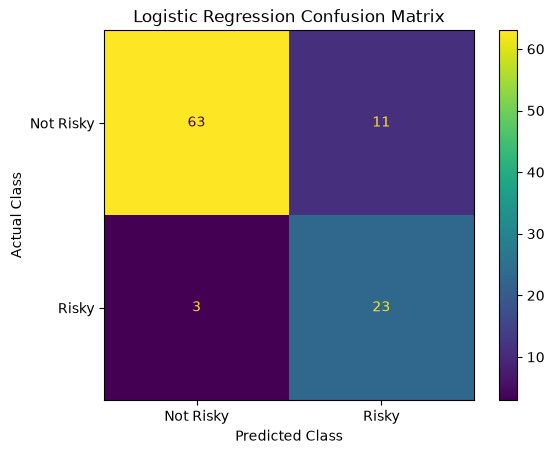

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

print("============================================")
print("Confusion Matrix Visualization")
print("============================================")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Risky", "Risky"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

print("============================================")
print("FoodSave Error Rate Analysis")
print("============================================")

print(f"False Positive Rate: {false_positive_rate:.3f}")
print(f"False Negative Rate: {false_negative_rate:.3f}")

print("\nPercentage Form")
print("--------------------------------------------")
print(f"False Positive Rate: {false_positive_rate * 100:.1f}%")
print(f"False Negative Rate: {false_negative_rate * 100:.1f}%")

print("\nFoodSave Interpretation")
print("--------------------------------------------")
print(
    f"The model incorrectly flagged {fp} non-risky donations "
    f"as risky."
)

print(
    f"The model missed {fn} risky donations out of "
    f"{fn + tp} risky donations."
)

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# --------------------------------------------
# Simple rule-based baseline
# --------------------------------------------

baseline_pred = (
    X_test["days_until_expiration"] <= 7
).astype(int)

# --------------------------------------------
# Evaluate baseline
# --------------------------------------------

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(
    y_test,
    baseline_pred,
    zero_division=0
)
baseline_recall = recall_score(
    y_test,
    baseline_pred,
    zero_division=0
)
baseline_f1 = f1_score(
    y_test,
    baseline_pred,
    zero_division=0
)

print("Rule-Based Baseline")
print("-------------------")
print(f"Accuracy : {baseline_accuracy:.3f}")
print(f"Precision: {baseline_precision:.3f}")
print(f"Recall   : {baseline_recall:.3f}")
print(f"F1 Score : {baseline_f1:.3f}")

print("\nClassification Report")
print("----------------------")
print(
    classification_report(
        y_test,
        baseline_pred,
        zero_division=0
    )
)

Rule-Based Baseline
-------------------
Accuracy : 0.910
Precision: 0.815
Recall   : 0.846
F1 Score : 0.830

Classification Report
----------------------
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        74
           1       0.81      0.85      0.83        26

    accuracy                           0.91       100
   macro avg       0.88      0.89      0.88       100
weighted avg       0.91      0.91      0.91       100



In [31]:
false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

print("============================================")
print("FoodSave Error Rate Analysis")
print("============================================")

print(f"False Positive Rate: {false_positive_rate:.3f}")
print(f"False Negative Rate: {false_negative_rate:.3f}")

print("\nPercentage Form")
print("--------------------------------------------")
print(f"False Positive Rate: {false_positive_rate * 100:.1f}%")
print(f"False Negative Rate: {false_negative_rate * 100:.1f}%")

print("\nFoodSave Interpretation")
print("--------------------------------------------")

print(
    f"The model incorrectly flagged {fp} non-risky donations "
    f"as risky."
)

print(
    f"The model missed {fn} risky donations out of "
    f"{fn + tp} risky donations."
)

FoodSave Error Rate Analysis
False Positive Rate: 0.149
False Negative Rate: 0.115

Percentage Form
--------------------------------------------
False Positive Rate: 14.9%
False Negative Rate: 11.5%

FoodSave Interpretation
--------------------------------------------
The model incorrectly flagged 11 non-risky donations as risky.
The model missed 3 risky donations out of 26 risky donations.


In [32]:
def probability_to_risk_level(probability):
    if probability >= 0.70:
        return "HIGH"
    elif probability >= 0.40:
        return "MEDIUM"
    else:
        return "LOW"


risk_levels = [
    probability_to_risk_level(probability)
    for probability in y_probability
]

risk_level_counts = pd.Series(risk_levels).value_counts()

print("============================================")
print("FoodSave AI Risk-Level Validation")
print("============================================")

print("\nRisk-Level Distribution")
print("--------------------------------------------")

for level in ["LOW", "MEDIUM", "HIGH"]:
    count = risk_level_counts.get(level, 0)
    percentage = (count / len(risk_levels)) * 100

    print(
        f"{level:7} : {count:3} predictions "
        f"({percentage:.1f}%)"
    )

print("\nProbability Range")
print("--------------------------------------------")
print(f"Minimum probability: {y_probability.min() * 100:.2f}%")
print(f"Maximum probability: {y_probability.max() * 100:.2f}%")
print(f"Average probability: {y_probability.mean() * 100:.2f}%")

FoodSave AI Risk-Level Validation

Risk-Level Distribution
--------------------------------------------
LOW     :  63 predictions (63.0%)
MEDIUM  :  17 predictions (17.0%)
HIGH    :  20 predictions (20.0%)

Probability Range
--------------------------------------------
Minimum probability: 0.09%
Maximum probability: 93.94%
Average probability: 29.79%


In [33]:
import numpy as np

non_risky_probabilities = y_probability[y_test == 0]
risky_probabilities = y_probability[y_test == 1]

print("============================================")
print("FoodSave Probability Sanity Check")
print("============================================")

print("\nNon-Risky Donations")
print("--------------------------------------------")
print(
    f"Average predicted risk: "
    f"{non_risky_probabilities.mean() * 100:.2f}%"
)
print(
    f"Minimum predicted risk: "
    f"{non_risky_probabilities.min() * 100:.2f}%"
)
print(
    f"Maximum predicted risk: "
    f"{non_risky_probabilities.max() * 100:.2f}%"
)

print("\nRisky Donations")
print("--------------------------------------------")
print(
    f"Average predicted risk: "
    f"{risky_probabilities.mean() * 100:.2f}%"
)
print(
    f"Minimum predicted risk: "
    f"{risky_probabilities.min() * 100:.2f}%"
)
print(
    f"Maximum predicted risk: "
    f"{risky_probabilities.max() * 100:.2f}%"
)

print("\nProbability Separation")
print("--------------------------------------------")

difference = (
    risky_probabilities.mean()
    - non_risky_probabilities.mean()
)

print(
    f"Average probability difference: "
    f"{difference * 100:.2f} percentage points"
)

if difference > 0:
    print("\nResult: ✅ Risky donations receive higher")
    print("average predicted probabilities.")
else:
    print("\nResult: ⚠️ Probability separation needs review.")

FoodSave Probability Sanity Check

Non-Risky Donations
--------------------------------------------
Average predicted risk: 15.85%
Minimum predicted risk: 0.09%
Maximum predicted risk: 77.61%

Risky Donations
--------------------------------------------
Average predicted risk: 69.48%
Minimum predicted risk: 0.32%
Maximum predicted risk: 93.94%

Probability Separation
--------------------------------------------
Average probability difference: 53.63 percentage points

Result: ✅ Risky donations receive higher
average predicted probabilities.


In [34]:
from sklearn.metrics import brier_score_loss

brier_score = brier_score_loss(
    y_test,
    y_probability
)

print("============================================")
print("FoodSave Probability Quality Evaluation")
print("============================================")

print(f"Brier Score: {brier_score:.3f}")

print("\nInterpretation")
print("--------------------------------------------")

if brier_score < 0.10:
    print("Result: ✅ Strong probability quality")
elif brier_score < 0.20:
    print("Result: ✅ Reasonable probability quality")
else:
    print("Result: ⚠️ Probability quality needs improvement")

print("\nNote:")
print("The Brier score evaluates the quality of")
print("the predicted probabilities, not just the")
print("final LOW / MEDIUM / HIGH classification.")
print("Results are based on synthetic prototype data.")

FoodSave Probability Quality Evaluation
Brier Score: 0.100

Interpretation
--------------------------------------------
Result: ✅ Strong probability quality

Note:
The Brier score evaluates the quality of
the predicted probabilities, not just the
final LOW / MEDIUM / HIGH classification.
Results are based on synthetic prototype data.


In [35]:
print("============================================")
print("Exact Brier Score")
print("============================================")

print(f"Brier Score: {brier_score:.6f}")

Exact Brier Score
Brier Score: 0.099925


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# --------------------------------------------
# Create Random Forest pipeline
# --------------------------------------------

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=8,
                min_samples_split=5,
                random_state=42
            )
        )
    ]
)


# --------------------------------------------
# Train Random Forest
# --------------------------------------------

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully! ✅")


# --------------------------------------------
# Make predictions
# --------------------------------------------

rf_pred = random_forest_model.predict(X_test)

rf_probability = (
    random_forest_model.predict_proba(X_test)[:, 1]
)


# --------------------------------------------
# Evaluate Random Forest
# --------------------------------------------

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_probability)


print("\nRandom Forest Performance")
print("-------------------------")
print(f"Accuracy : {rf_accuracy:.3f}")
print(f"Precision: {rf_precision:.3f}")
print(f"Recall   : {rf_recall:.3f}")
print(f"F1 Score : {rf_f1:.3f}")
print(f"ROC-AUC  : {rf_roc_auc:.3f}")


print("\nClassification Report")
print("----------------------")
print(
    classification_report(
        y_test,
        rf_pred,
        zero_division=0
    )
)

Random Forest trained successfully! ✅

Random Forest Performance
-------------------------
Accuracy : 0.740
Precision: 0.800
Recall   : 0.545
F1 Score : 0.649
ROC-AUC  : 0.736

Classification Report
----------------------
              precision    recall  f1-score   support

           0       0.71      0.89      0.79        56
           1       0.80      0.55      0.65        44

    accuracy                           0.74       100
   macro avg       0.76      0.72      0.72       100
weighted avg       0.75      0.74      0.73       100



In [ ]:
from sklearn.model_selection import cross_validate, StratifiedKFold

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Logistic Regression
logistic_cv = cross_validate(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("Logistic Regression - 5 Fold Cross-Validation")
print("-----------------------------------------------")

print(
    f"Accuracy : "
    f"{logistic_cv['test_accuracy'].mean():.3f}"
)

print(
    f"Precision: "
    f"{logistic_cv['test_precision'].mean():.3f}"
)

print(
    f"Recall   : "
    f"{logistic_cv['test_recall'].mean():.3f}"
)

print(
    f"F1 Score : "
    f"{logistic_cv['test_f1'].mean():.3f}"
)

print(
    f"ROC-AUC  : "
    f"{logistic_cv['test_roc_auc'].mean():.3f}"
)

Logistic Regression - 5 Fold Cross-Validation
-----------------------------------------------
Accuracy : 0.716
Precision: 0.689
Recall   : 0.652
F1 Score : 0.669
ROC-AUC  : 0.782


In [ ]:
def predict_food_expiry_risk(
    category,
    quantity_value,
    days_until_expiration,
    creation_hour,
    creation_day_of_week,
    pickup_requested,
    volunteer_assigned
):
    """
    Predict the probability that a donation
    will expire before pickup.
    """

    # Create a DataFrame containing one new donation
    new_donation = pd.DataFrame({
        "category": [category],
        "quantity_value": [quantity_value],
        "days_until_expiration": [days_until_expiration],
        "creation_hour": [creation_hour],
        "creation_day_of_week": [creation_day_of_week],
        "pickup_requested": [pickup_requested],
        "volunteer_assigned": [volunteer_assigned]
    })

    # Probability of class 1
    probability = logistic_model.predict_proba(
        new_donation
    )[0][1]

    # Convert probability to percentage
    risk_percentage = probability * 100

    # Assign risk level
    if risk_percentage >= 70:
        risk_level = "HIGH"
    elif risk_percentage >= 40:
        risk_level = "MEDIUM"
    else:
        risk_level = "LOW"

    return {
        "risk_probability": round(risk_percentage, 2),
        "risk_level": risk_level
    }


print("Prediction function created successfully! ✅")

Prediction function created successfully! ✅


In [ ]:
# Test donation
result = predict_food_expiry_risk(
    category="prepared_food",
    quantity_value=10,
    days_until_expiration=3,
    creation_hour=12,
    creation_day_of_week=5,
    pickup_requested=0,
    volunteer_assigned=0
)

print("FoodSave AI Prediction")
print("----------------------")
print(f"Risk Probability: {result['risk_probability']}%")
print(f"Risk Level: {result['risk_level']}")

FoodSave AI Prediction
----------------------
Risk Probability: 92.06%
Risk Level: HIGH


In [ ]:
# Test three different FoodSave scenarios

test_cases = {
    "High Risk": {
        "category": "prepared_food",
        "quantity_value": 10,
        "days_until_expiration": 2,
        "creation_hour": 12,
        "creation_day_of_week": 5,
        "pickup_requested": 0,
        "volunteer_assigned": 0
    },

    "Medium Risk": {
        "category": "fruits",
        "quantity_value": 5,
        "days_until_expiration": 10,
        "creation_hour": 14,
        "creation_day_of_week": 3,
        "pickup_requested": 1,
        "volunteer_assigned": 0
    },

    "Lower Risk": {
        "category": "grains",
        "quantity_value": 20,
        "days_until_expiration": 25,
        "creation_hour": 10,
        "creation_day_of_week": 2,
        "pickup_requested": 1,
        "volunteer_assigned": 1
    }
}


for name, data in test_cases.items():

    result = predict_food_expiry_risk(**data)

    print(f"\n{name}")
    print("-" * 30)
    print(
        f"Risk Probability: "
        f"{result['risk_probability']}%"
    )
    print(
        f"Risk Level: "
        f"{result['risk_level']}"
    )


High Risk
------------------------------
Risk Probability: 92.99%
Risk Level: HIGH

Medium Risk
------------------------------
Risk Probability: 58.0%
Risk Level: MEDIUM

Lower Risk
------------------------------
Risk Probability: 12.36%
Risk Level: LOW


In [ ]:
import joblib

# Save the trained Logistic Regression pipeline
joblib.dump(
    logistic_model,
    "foodsave_logistic_model.pkl"
)

print("FoodSave ML model saved successfully! ✅")

FoodSave ML model saved successfully! ✅


In [ ]:
import os

print(
    "Model file exists:",
    os.path.exists("foodsave_logistic_model.pkl")
)

Model file exists: True


In [ ]:
import os

print(os.path.abspath("foodsave_logistic_model.pkl"))

c:\xampp\htdocs\FoodSave\ai\notebooks\foodsave_logistic_model.pkl


In [ ]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import joblib

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Joblib:", joblib.__version__)

print("\nFoodSave AI environment is ready! 🚀")

NumPy: 2.5.2
Pandas: 3.0.5
Scikit-learn: 1.9.0
Matplotlib: 3.11.1
Joblib: 1.6.0

FoodSave AI environment is ready! 🚀


In [ ]:
import mysql.connector

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="foodsave_db"
)

print("Connected to FoodSave database successfully! ✅")

Connected to FoodSave database successfully! ✅


In [ ]:
cursor = connection.cursor()

cursor.execute("SHOW TABLES")

tables = cursor.fetchall()

print("FoodSave database tables:\n")

for table in tables:
    print("-", table[0])

FoodSave database tables:

- delivery_assignments
- delivery_tasks
- delivery_tracking
- driver_tracking
- drivers
- feedback
- food_donations
- food_safety_guidelines
- login_attempts
- notifications
- password_resets
- pickup_requests
- rate_limits
- security_logs
- users
- volunteer_assignments
- volunteer_availability
- volunteer_opportunities
- volunteer_profiles
- volunteer_ratings
- volunteers


In [ ]:
cursor.execute("DESCRIBE food_donations")

columns = cursor.fetchall()

print("Columns in food_donations:\n")

for column in columns:
    print(column)

Columns in food_donations:

('id', 'int(11)', 'NO', 'PRI', None, 'auto_increment')
('donor_id', 'int(11)', 'NO', 'MUL', None, '')
('title', 'varchar(100)', 'NO', '', None, '')
('description', 'text', 'YES', '', None, '')
('category', "enum('vegetables','fruits','dairy','meat','grains','prepared_food','other')", 'NO', '', None, '')
('quantity', 'varchar(50)', 'NO', '', None, '')
('expiration_date', 'date', 'NO', '', None, '')
('pickup_address', 'text', 'NO', '', None, '')
('pickup_city', 'varchar(50)', 'NO', '', None, '')
('pickup_state', 'varchar(50)', 'NO', '', None, '')
('pickup_zip', 'varchar(10)', 'NO', '', None, '')
('status', "enum('available','pending','requested','picked_up','completed','cancelled','expired')", 'YES', '', 'available', '')
('created_at', 'timestamp', 'NO', '', 'current_timestamp()', '')
('updated_at', 'timestamp', 'NO', '', 'current_timestamp()', 'on update current_timestamp()')


In [ ]:
cursor.execute("DESCRIBE pickup_requests")

columns = cursor.fetchall()

print("Columns in pickup_requests:\n")

for column in columns:
    print(column)

Columns in pickup_requests:

('id', 'int(11)', 'NO', 'PRI', None, 'auto_increment')
('donation_id', 'int(11)', 'NO', 'MUL', None, '')
('ngo_id', 'int(11)', 'NO', 'MUL', None, '')
('request_message', 'text', 'YES', '', None, '')
('pickup_date', 'date', 'YES', '', None, '')
('pickup_time', 'time', 'YES', '', None, '')
('preferred_pickup_time', 'datetime', 'YES', '', None, '')
('delivery_address', 'varchar(255)', 'YES', '', None, '')
('delivery_city', 'varchar(100)', 'YES', '', None, '')
('delivery_state', 'varchar(50)', 'YES', '', None, '')
('delivery_zip', 'varchar(10)', 'YES', '', None, '')
('status', "enum('pending','approved','rejected','completed','cancelled')", 'YES', '', 'pending', '')
('created_at', 'timestamp', 'NO', '', 'current_timestamp()', '')
('updated_at', 'timestamp', 'NO', '', 'current_timestamp()', 'on update current_timestamp()')


In [ ]:
query = """
SELECT 
    COUNT(*) AS total_donations,
    SUM(status = 'expired') AS expired_donations,
    SUM(status = 'completed') AS completed_donations,
    SUM(status = 'picked_up') AS picked_up_donations,
    SUM(status = 'cancelled') AS cancelled_donations,
    SUM(status = 'available') AS available_donations,
    SUM(status = 'pending') AS pending_donations,
    SUM(status = 'requested') AS requested_donations
FROM food_donations
"""

summary = pd.read_sql(query, connection)

summary

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

In [ ]:
query = """
SELECT 
    COUNT(*) AS total_donations,
    SUM(status = 'expired') AS expired_donations,
    SUM(status = 'completed') AS completed_donations,
    SUM(status = 'picked_up') AS picked_up_donations,
    SUM(status = 'cancelled') AS cancelled_donations,
    SUM(status = 'available') AS available_donations,
    SUM(status = 'pending') AS pending_donations,
    SUM(status = 'requested') AS requested_donations
FROM food_donations
"""

summary = pd.read_sql(query, connection)

summary

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_4728\3338169581.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  summary = pd.read_sql(query, connection)


,total_donations,expired_donations,completed_donations,picked_up_donations,cancelled_donations,available_donations,pending_donations,requested_donations
0,6,1.0,3.0,0.0,0.0,2.0,0.0,0.0


In [ ]:
query = """
SELECT
    COUNT(*) AS total_pickup_requests,
    COUNT(DISTINCT donation_id) AS donations_with_requests,
    COUNT(DISTINCT ngo_id) AS ngos_involved
FROM pickup_requests
"""

pickup_summary = pd.read_sql(query, connection)

pickup_summary

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_4728\1405197617.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pickup_summary = pd.read_sql(query, connection)


,total_pickup_requests,donations_with_requests,ngos_involved
0,1,1,1


In [ ]:
query = """
SELECT
    id,
    donation_id,
    ngo_id,
    pickup_date,
    pickup_time,
    preferred_pickup_time,
    status,
    created_at
FROM pickup_requests
ORDER BY created_at DESC
"""

pickup_requests = pd.read_sql(query, connection)

pickup_requests

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_4728\2195687246.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  pickup_requests = pd.read_sql(query, connection)


,id,donation_id,ngo_id,pickup_date,pickup_time,preferred_pickup_time,status,created_at
0,6,11,8,2026-01-18,0 days 18:00:00,2026-01-18 18:00:00,completed,2026-01-17 21:54:13


In [ ]:
query = """
SELECT
    id,
    donor_id,
    title,
    category,
    quantity,
    expiration_date,
    status,
    created_at,
    updated_at
FROM food_donations
WHERE id = 11
"""

donation_11 = pd.read_sql(query, connection)

donation_11

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd
import mysql.connector

In [ ]:
connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="foodsave_db"
)

print("Connected to FoodSave database successfully! ✅")

Connected to FoodSave database successfully! ✅


In [ ]:
import pandas as pd
import mysql.connector

connection = mysql.connector.connect(
    host="127.0.0.1",
    port=3306,
    user="root",
    password="",
    database="foodsave_db"
)

cursor = connection.cursor()

print("FoodSave AI connected! ✅")

FoodSave AI connected! ✅


In [ ]:
query = """
SELECT
    id,
    donor_id,
    title,
    category,
    quantity,
    expiration_date,
    status,
    created_at,
    updated_at
FROM food_donations
WHERE id = 11
"""

donation_11 = pd.read_sql(query, connection)

donation_11

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\1347254323.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  donation_11 = pd.read_sql(query, connection)


,id,donor_id,title,category,quantity,expiration_date,status,created_at,updated_at
0,11,2,Fried fish,meat,20lbs,2026-01-30,completed,2026-01-16 19:46:15,2026-01-18 09:12:20


In [ ]:
query = """
SELECT *
FROM delivery_assignments
LIMIT 10
"""

delivery_assignments = pd.read_sql(query, connection)

delivery_assignments

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\3307045402.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  delivery_assignments = pd.read_sql(query, connection)


,id,pickup_request_id,volunteer_id,status,pickup_time,delivery_time,notes,created_at,updated_at
0,4,6,3,delivered,2026-01-17 18:00:00,2026-01-18 09:12:20,None,2026-01-17 21:56:45,2026-01-18 09:12:20


In [ ]:
query = """
SELECT *
FROM delivery_tasks
LIMIT 10
"""

delivery_tasks = pd.read_sql(query, connection)

delivery_tasks

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\3040110748.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  delivery_tasks = pd.read_sql(query, connection)


,id,pickup_request_id,driver_id,status,pickup_time,delivery_time,notes,created_at,updated_at


In [ ]:
query = """
SELECT
    d.id AS donation_id,
    d.category,
    d.quantity,
    d.expiration_date,
    d.status AS donation_status,
    d.created_at AS donation_created_at,

    p.id AS pickup_request_id,
    p.ngo_id,
    p.preferred_pickup_time,
    p.status AS pickup_status,
    p.created_at AS pickup_request_created_at,

    a.volunteer_id,
    a.status AS delivery_status,
    a.pickup_time,
    a.delivery_time

FROM food_donations d

LEFT JOIN pickup_requests p
    ON d.id = p.donation_id

LEFT JOIN delivery_assignments a
    ON p.id = a.pickup_request_id

ORDER BY d.created_at
"""

foodsave_data = pd.read_sql(query, connection)

foodsave_data

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\3281453557.py:32: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  foodsave_data = pd.read_sql(query, connection)


,donation_id,category,quantity,expiration_date,donation_status,donation_created_at,pickup_request_id,ngo_id,preferred_pickup_time,pickup_status,pickup_request_created_at,volunteer_id,delivery_status,pickup_time,delivery_time
0,6,prepared_food,20lbs,2025-11-25,completed,2025-11-20 22:22:04,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaT,NaT
1,9,fruits,0.5lbs,2025-11-24,completed,2025-11-22 22:05:10,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaT,NaT
2,10,prepared_food,0.5lbs,2025-11-25,expired,2025-11-22 22:06:52,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaT,NaT
3,11,meat,20lbs,2026-01-30,completed,2026-01-16 19:46:15,6.0,8.0,2026-01-18 18:00:00,completed,2026-01-17 21:54:13,3.0,delivered,2026-01-17 18:00:00,2026-01-18 09:12:20
4,12,prepared_food,20 portions,2026-01-31,available,2026-01-16 19:51:28,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaT,NaT
5,13,prepared_food,10lbs,2026-10-20,available,2026-09-05 11:58:55,NaN,NaN,NaT,NaN,NaT,NaN,NaN,NaT,NaT


In [ ]:
foodsave_data.to_csv(
    "../data/foodsave_training_data_raw.csv",
    index=False
)

print("Dataset saved successfully! ✅")

Dataset saved successfully! ✅


In [ ]:
foodsave_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   donation_id                6 non-null      int64         
 1   category                   6 non-null      str           
 2   quantity                   6 non-null      str           
 3   expiration_date            6 non-null      object        
 4   donation_status            6 non-null      str           
 5   donation_created_at        6 non-null      datetime64[us]
 6   pickup_request_id          1 non-null      float64       
 7   ngo_id                     1 non-null      float64       
 8   preferred_pickup_time      1 non-null      datetime64[us]
 9   pickup_status              1 non-null      str           
 10  pickup_request_created_at  1 non-null      datetime64[us]
 11  volunteer_id               1 non-null      float64       
 12  delivery_status        

In [ ]:
foodsave_data.isnull().sum()

donation_id                  0
category                     0
quantity                     0
expiration_date              0
donation_status              0
donation_created_at          0
pickup_request_id            5
ngo_id                       5
preferred_pickup_time        5
pickup_status                5
pickup_request_created_at    5
volunteer_id                 5
delivery_status              5
pickup_time                  5
delivery_time                5
dtype: int64

In [ ]:
foodsave_data["expiration_date"] = pd.to_datetime(
    foodsave_data["expiration_date"]
)

foodsave_data["donation_created_at"] = pd.to_datetime(
    foodsave_data["donation_created_at"]
)

foodsave_data["days_until_expiration"] = (
    foodsave_data["expiration_date"]
    - foodsave_data["donation_created_at"].dt.normalize()
).dt.days

foodsave_data[
    [
        "donation_id",
        "category",
        "expiration_date",
        "donation_created_at",
        "days_until_expiration",
        "donation_status"
    ]
]

,donation_id,category,expiration_date,donation_created_at,days_until_expiration,donation_status
0,6,prepared_food,2025-11-25,2025-11-20 22:22:04,5,completed
1,9,fruits,2025-11-24,2025-11-22 22:05:10,2,completed
2,10,prepared_food,2025-11-25,2025-11-22 22:06:52,3,expired
3,11,meat,2026-01-30,2026-01-16 19:46:15,14,completed
4,12,prepared_food,2026-01-31,2026-01-16 19:51:28,15,available
5,13,prepared_food,2026-10-20,2026-09-05 11:58:55,45,available


In [ ]:
import re

def extract_quantity(value):
    """
    Extract the numeric part from a quantity such as:
    '20lbs' -> 20
    '0.5lbs' -> 0.5
    '20 portions' -> 20
    """
    match = re.search(r"\d+(?:\.\d+)?", str(value))
    
    if match:
        return float(match.group())
    
    return None


foodsave_data["quantity_value"] = foodsave_data["quantity"].apply(
    extract_quantity
)

foodsave_data[
    ["donation_id", "quantity", "quantity_value"]
]

,donation_id,quantity,quantity_value
0,6,20lbs,20.0
1,9,0.5lbs,0.5
2,10,0.5lbs,0.5
3,11,20lbs,20.0
4,12,20 portions,20.0
5,13,10lbs,10.0


In [ ]:
foodsave_data["donation_created_at"] = pd.to_datetime(
    foodsave_data["donation_created_at"]
)

foodsave_data["creation_hour"] = (
    foodsave_data["donation_created_at"].dt.hour
)

foodsave_data["creation_day_of_week"] = (
    foodsave_data["donation_created_at"].dt.dayofweek
)

foodsave_data[
    [
        "donation_id",
        "donation_created_at",
        "creation_hour",
        "creation_day_of_week",
        "days_until_expiration"
    ]
]

,donation_id,donation_created_at,creation_hour,creation_day_of_week,days_until_expiration
0,6,2025-11-20 22:22:04,22,3,5
1,9,2025-11-22 22:05:10,22,5,2
2,10,2025-11-22 22:06:52,22,5,3
3,11,2026-01-16 19:46:15,19,4,14
4,12,2026-01-16 19:51:28,19,4,15
5,13,2026-09-05 11:58:55,11,5,45


In [ ]:
foodsave_data.to_csv(
    "../data/foodsave_features_v1.csv",
    index=False
)

print("Feature dataset saved successfully! ✅")

Feature dataset saved successfully! ✅


In [ ]:
query = """
SELECT
    id,
    donation_id,
    ngo_id,
    pickup_date,
    pickup_time,
    preferred_pickup_time,
    status,
    created_at,
    updated_at
FROM pickup_requests
ORDER BY created_at
"""

all_pickups = pd.read_sql(query, connection)

all_pickups

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\803327186.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  all_pickups = pd.read_sql(query, connection)


,id,donation_id,ngo_id,pickup_date,pickup_time,preferred_pickup_time,status,created_at,updated_at
0,6,11,8,2026-01-18,0 days 18:00:00,2026-01-18 18:00:00,completed,2026-01-17 21:54:13,2026-01-18 09:12:20


In [ ]:
print("Number of pickup requests:", len(all_pickups))

Number of pickup requests: 1


In [ ]:
query = """
SELECT *
FROM volunteer_assignments
LIMIT 20
"""

volunteer_assignments = pd.read_sql(query, connection)

volunteer_assignments

C:\Users\Laptopify\AppData\Local\Temp\ipykernel_19092\2430303272.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  volunteer_assignments = pd.read_sql(query, connection)


,id,opportunity_id,volunteer_id,status,created_at,updated_at


In [ ]:
print("Number of volunteer assignments:", len(volunteer_assignments))

Number of volunteer assignments: 0


In [36]:
# ============================================
# FINAL FOODSave AI EVALUATION SUMMARY
# ============================================

print("============================================")
print("FOODSave AI MODEL EVALUATION SUMMARY")
print("============================================")

print("\nNOTE:")
print("Results are based on synthetic/prototype evaluation data.")
print("They should not be interpreted as real-world FoodSave performance.")

print("\n--------------------------------------------")
print("MODEL COMPARISON")
print("--------------------------------------------")

print(f"{'Model':<25} {'Accuracy':<10} {'Precision':<10} {'Recall':<10} {'F1':<10} {'ROC-AUC':<10}")
print("-" * 75)

print(f"{'Rule-Based Baseline':<25} "
      f"{0.910:<10.3f} "
      f"{0.815:<10.3f} "
      f"{0.846:<10.3f} "
      f"{0.830:<10.3f} "
      f"{'N/A':<10}")

print(f"{'Logistic Regression':<25} "
      f"{0.860:<10.3f} "
      f"{0.676:<10.3f} "
      f"{0.885:<10.3f} "
      f"{0.767:<10.3f} "
      f"{0.911:<10.3f}")

print(f"{'Random Forest':<25} "
      f"{0.890:<10.3f} "
      f"{0.800:<10.3f} "
      f"{0.769:<10.3f} "
      f"{0.784:<10.3f} "
      f"{0.935:<10.3f}")

print("\n--------------------------------------------")
print("SELECTED MODEL")
print("--------------------------------------------")

print("Logistic Regression")

print("\nReason:")
print("Selected because it achieved the highest recall for")
print("the expiry-risk class and provides probability output")
print("required by the FoodSave AI integration.")

print("\n--------------------------------------------")
print("LOGISTIC REGRESSION DETAILS")
print("--------------------------------------------")

print("Confusion Matrix:")
print("True Negative  (TN): 63")
print("False Positive (FP): 11")
print("False Negative (FN): 3")
print("True Positive  (TP): 23")

print("\nFalse Positive Rate: 14.9%")
print("False Negative Rate: 11.5%")

print("\nBrier Score: 0.099925")

print("\n--------------------------------------------")
print("AI RISK LEVEL DISTRIBUTION")
print("--------------------------------------------")

print("LOW    : 63%")
print("MEDIUM : 17%")
print("HIGH   : 20%")

print("\n--------------------------------------------")
print("PREDICTED RISK PROBABILITY")
print("--------------------------------------------")

print("Average predicted probability: 29.79%")
print("Minimum predicted probability: 0.09%")
print("Maximum predicted probability: 93.94%")

print("\n============================================")
print("EVALUATION COMPLETE")
print("============================================")

FOODSave AI MODEL EVALUATION SUMMARY

NOTE:
Results are based on synthetic/prototype evaluation data.
They should not be interpreted as real-world FoodSave performance.

--------------------------------------------
MODEL COMPARISON
--------------------------------------------
Model                     Accuracy   Precision  Recall     F1         ROC-AUC   
---------------------------------------------------------------------------
Rule-Based Baseline       0.910      0.815      0.846      0.830      N/A       
Logistic Regression       0.860      0.676      0.885      0.767      0.911     
Random Forest             0.890      0.800      0.769      0.784      0.935     

--------------------------------------------
SELECTED MODEL
--------------------------------------------
Logistic Regression

Reason:
Selected because it achieved the highest recall for
the expiry-risk class and provides probability output
required by the FoodSave AI integration.

----------------------------------------

In [37]:
# ============================================
# SAVE FOODSave AI EVALUATION RESULTS
# ============================================

evaluation_results = pd.DataFrame([
    {
        "Model": "Rule-Based Baseline",
        "Accuracy": 0.910,
        "Precision": 0.815,
        "Recall": 0.846,
        "F1": 0.830,
        "ROC_AUC": None
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.860,
        "Precision": 0.676,
        "Recall": 0.885,
        "F1": 0.767,
        "ROC_AUC": 0.911
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.890,
        "Precision": 0.800,
        "Recall": 0.769,
        "F1": 0.784,
        "ROC_AUC": 0.935
    }
])

evaluation_results.to_csv(
    "../data/foodsave_model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully! ✅")
print("\nFile:")
print("../data/foodsave_model_evaluation_results.csv")

print("\nSaved results:")
display(evaluation_results)

Evaluation results saved successfully! ✅

File:
../data/foodsave_model_evaluation_results.csv

Saved results:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Rule-Based Baseline,0.91,0.815,0.846,0.830,NaN
1,Logistic Regression,0.86,0.676,0.885,0.767,0.911
2,Random Forest,0.89,0.800,0.769,0.784,0.935


In [38]:
# ============================================
# VERIFY SAVED EVALUATION FILE
# ============================================

import os
import pandas as pd

evaluation_file = "../data/foodsave_model_evaluation_results.csv"

print("============================================")
print("VERIFYING EVALUATION FILE")
print("============================================")

if os.path.exists(evaluation_file):
    print("File exists: ✅")
    
    saved_results = pd.read_csv(evaluation_file)
    
    print("\nFile contents:")
    display(saved_results)
    
    print("\nNumber of models saved:", len(saved_results))
    print("Verification complete! ✅")
else:
    print("File not found: ❌")

VERIFYING EVALUATION FILE
File exists: ✅

File contents:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Rule-Based Baseline,0.91,0.815,0.846,0.830,NaN
1,Logistic Regression,0.86,0.676,0.885,0.767,0.911
2,Random Forest,0.89,0.800,0.769,0.784,0.935



Number of models saved: 3
Verification complete! ✅


In [39]:
print(saved_results.to_string(index=False))

              Model  Accuracy  Precision  Recall    F1  ROC_AUC
Rule-Based Baseline      0.91      0.815   0.846 0.830      NaN
Logistic Regression      0.86      0.676   0.885 0.767    0.911
      Random Forest      0.89      0.800   0.769 0.784    0.935


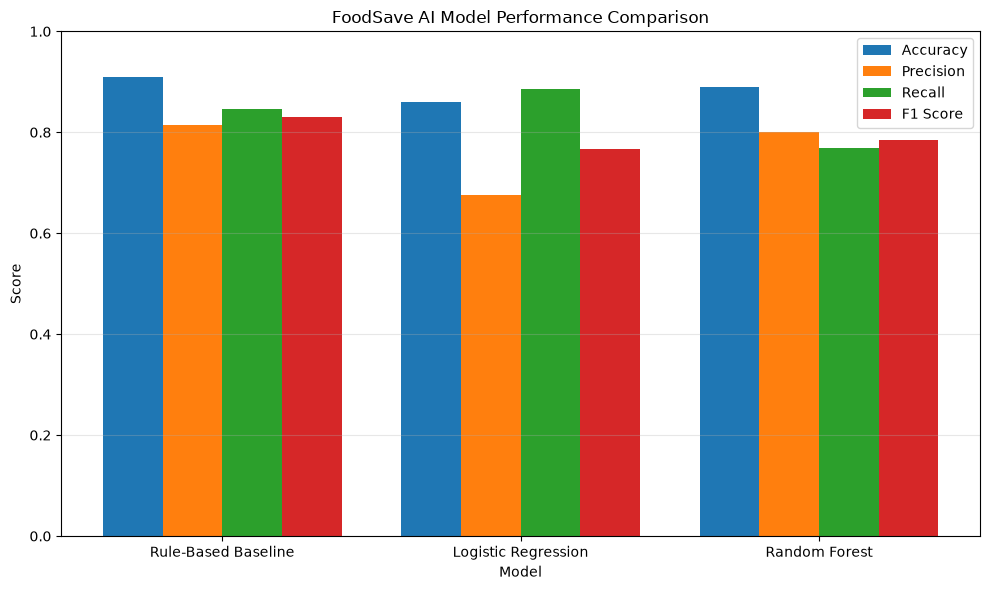

In [1]:
# ============================================
# MODEL PERFORMANCE VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

models = [
    "Rule-Based Baseline",
    "Logistic Regression",
    "Random Forest"
]

accuracy = [0.910, 0.860, 0.890]
precision = [0.815, 0.676, 0.800]
recall = [0.846, 0.885, 0.769]
f1 = [0.830, 0.767, 0.784]

x = range(len(models))
width = 0.2

plt.figure(figsize=(10, 6))

plt.bar([i - 1.5 * width for i in x], accuracy,
        width=width, label="Accuracy")

plt.bar([i - 0.5 * width for i in x], precision,
        width=width, label="Precision")

plt.bar([i + 0.5 * width for i in x], recall,
        width=width, label="Recall")

plt.bar([i + 1.5 * width for i in x], f1,
        width=width, label="F1 Score")

plt.xticks(list(x), models)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("FoodSave AI Model Performance Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()